In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from mytools.halo_new import get_coord, get_mask_sector, get_mask_square 
from mytools.plot import plot_heatmap, plot_stack_fit_res, plot_axlines
from crafts_stack.halo_nfw import gen_test_data, build_model, halofit

<Axes: title={'center': 'Test'}, xlabel='X', ylabel='Y'>

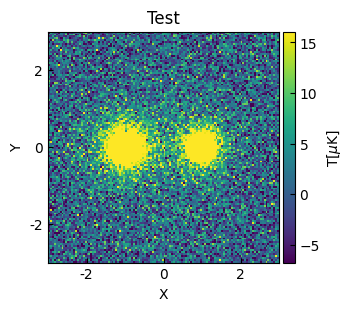

In [3]:
coord = get_coord()
kw_h1 = {
    "amplitude": 50,
    "x_mean": -1,
    "y_mean": 0,
    "r_s": 0.6,
}
noise_std = 5
data = gen_test_data(*coord, kw_h1=kw_h1, noise_std=noise_std)
plot_heatmap(data, title='Test')

In [4]:
model = build_model()
print(model)

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=50., x_mean=-1., y_mean=0., r_s=0.5)>

    [1]: <NFW2D(amplitude=50., x_mean=1., y_mean=0., r_s=0.5)>

    [2]: <Const2D(amplitude=0.)>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 r_s_0 ... x_mean_1 y_mean_1 r_s_1 amplitude_2
    ----------- -------- -------- ----- ... -------- -------- ----- -----------
           50.0     -1.0      0.0   0.5 ...      1.0      0.0   0.5         0.0


# without mask

In [5]:
data_list, fit_info = halofit(coord, data, model=model, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=49.76933493, x_mean=-0.99996475, y_mean=0.00005743, r_s=0.60191452)>

    [1]: <NFW2D(amplitude=50.31623088, x_mean=1.00000829, y_mean=0.0001115, r_s=0.49734509)>

    [2]: <Const2D(amplitude=0.00855894)>
Parameters:
       amplitude_0          x_mean_0      ...     amplitude_2     
    ----------------- ------------------- ... --------------------
    49.76933492526137 -0.9999647476991551 ... 0.008558941059156487

Goodness of fit:
Chi-squared: 361282.992
RMS residual: 5.009


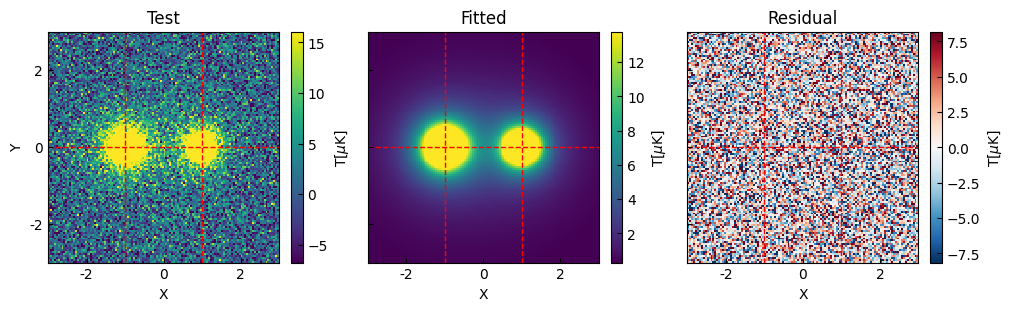

In [6]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list, title=title)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask sector 

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

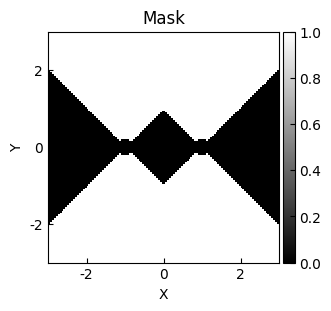

In [7]:
mask = get_mask_sector(coord=coord)
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [8]:
data_list_sector, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=52.51907434, x_mean=-0.99465275, y_mean=0.00131801, r_s=0.58281846)>

    [1]: <NFW2D(amplitude=51.78581269, x_mean=0.99782884, y_mean=-0.00015107, r_s=0.49076631)>

    [2]: <Const2D(amplitude=0.08446482)>
Parameters:
       amplitude_0          x_mean_0      ...       r_s_1           amplitude_2    
    ----------------- ------------------- ... ----------------- -------------------
    52.51907434087218 -0.9946527516794844 ... 0.490766314505758 0.08446482211234843

Goodness of fit:
Chi-squared: 407251.652
RMS residual: 5.318


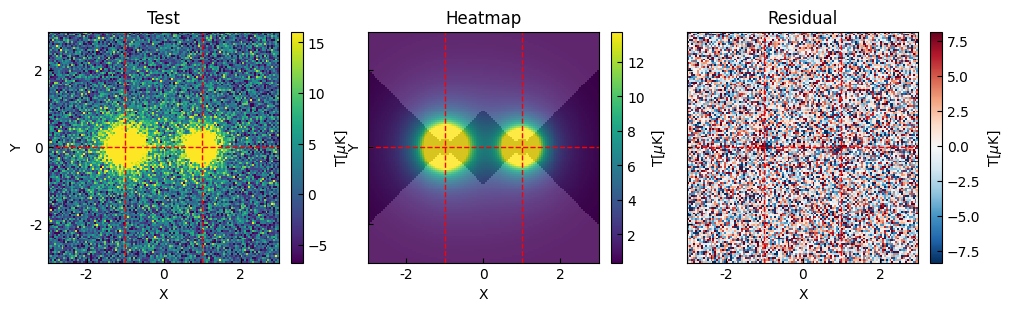

In [9]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_sector, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask square

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

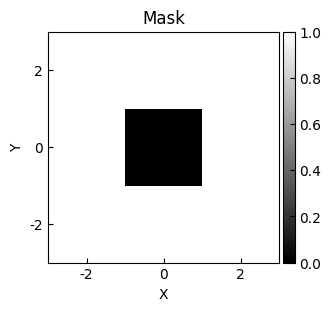

In [10]:
mask = ~get_mask_square(coord=coord)
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [11]:
data_list_square, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=51.52473675, x_mean=-0.99942622, y_mean=-0.00012042, r_s=0.58937073)>

    [1]: <NFW2D(amplitude=52.99145367, x_mean=0.99931591, y_mean=-0.00024682, r_s=0.48159348)>

    [2]: <Const2D(amplitude=0.03889236)>
Parameters:
       amplitude_0          x_mean_0      ...       r_s_1            amplitude_2    
    ----------------- ------------------- ... ------------------ -------------------
    51.52473675359448 -0.9994262170008807 ... 0.4815934808926157 0.03889236428233853

Goodness of fit:
Chi-squared: 363628.113
RMS residual: 5.025


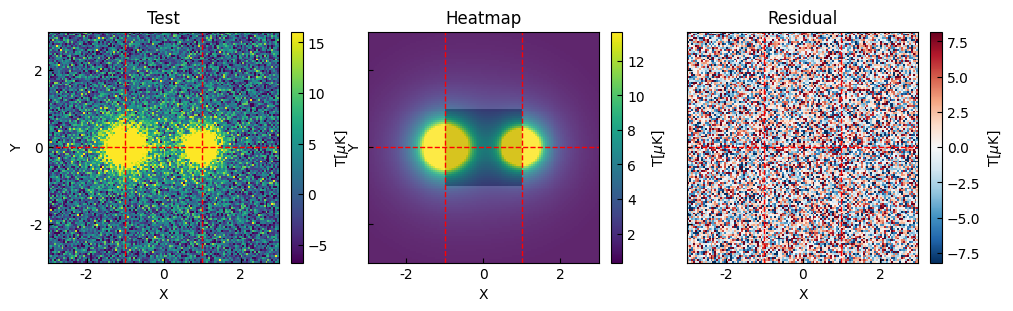

In [12]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# compare

In [13]:
from mytools.plot import plot_hist

(-20.0, 20.0)

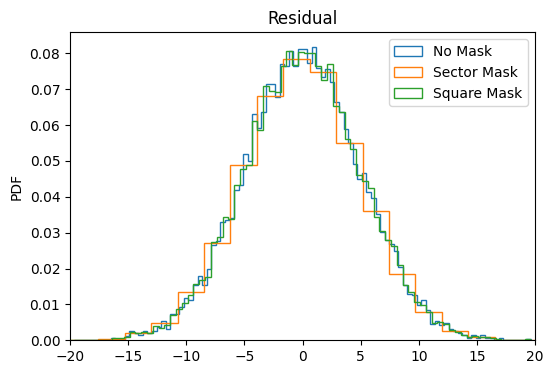

In [14]:
res_list = [data_list[-1].flatten(), data_list_sector[-1].flatten(), data_list_square[-1].flatten()]
title = ['No Mask', 'Sector Mask', 'Square Mask']
ax = plot_hist(res_list, label=title, bins=100, title='Residual')
ax.set_xlim(-20, 20)